# Exploração inicial: Olist Brazilian E-Commerce

Primeiro contato com os dados já carregados no PostgreSQL (`python -m src.pipeline`). O objetivo aqui é entender volume, cobertura temporal, distribuições e problemas de qualidade antes de escrever as queries analíticas em `sql/analysis/`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

from src.config import get_engine

engine = get_engine()
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e1e0d9'})
BLUE, ORANGE = '#2a78d6', '#eb6834'

def q(sql: str) -> pd.DataFrame:
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

## 1. Volume por tabela

In [2]:
tables = ['orders', 'order_items', 'order_payments', 'order_reviews', 'customers',
          'products', 'sellers', 'geolocation', 'category_translation']
pd.DataFrame({'linhas': [q(f'SELECT COUNT(*) AS n FROM {t}').n[0] for t in tables]}, index=tables)

,linhas
orders,99441
order_items,112650
order_payments,103886
order_reviews,99224
customers,99441
products,32951
sellers,3095
geolocation,1000163
category_translation,71


## 2. Cobertura temporal

As pontas da série têm pouquíssimos pedidos. Por isso as análises de sazonalidade usam o recorte **jan/2017 a ago/2018**.

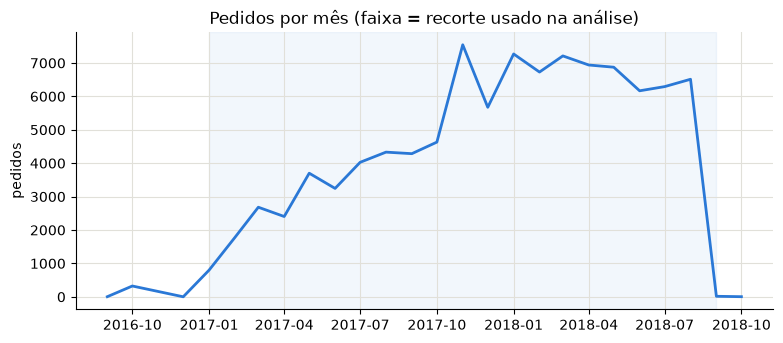

In [3]:
monthly = q("""
    SELECT DATE_TRUNC('month', order_purchase_timestamp)::date AS month, COUNT(*) AS orders
    FROM orders GROUP BY 1 ORDER BY 1
""")
ax = monthly.plot(x='month', y='orders', color=BLUE, legend=False, lw=2)
ax.axvspan(pd.Timestamp('2017-01-01'), pd.Timestamp('2018-08-31'), color=BLUE, alpha=0.06)
ax.set(title='Pedidos por mês (faixa = recorte usado na análise)', xlabel='', ylabel='pedidos');

## 3. Status dos pedidos

In [4]:
q('SELECT order_status, COUNT(*) AS pedidos FROM orders GROUP BY 1 ORDER BY 2 DESC').assign(pct=lambda d: (d.pedidos / d.pedidos.sum()).round(4))

,order_status,pedidos,pct
0,delivered,96478,0.9702
1,shipped,1107,0.0111
2,canceled,625,0.0063
3,unavailable,609,0.0061
4,invoiced,314,0.0032
5,processing,301,0.0030
6,created,5,0.0001
7,approved,2,0.0000


## 4. Distribuição das notas

Distribuição em "J": a maioria dá 5 estrelas, mas há um volume relevante de 1 estrela. Como a escala é ordinal e assimétrica, o teste estatístico usado depois é o **Mann-Whitney U** (não paramétrico), e não um teste t.

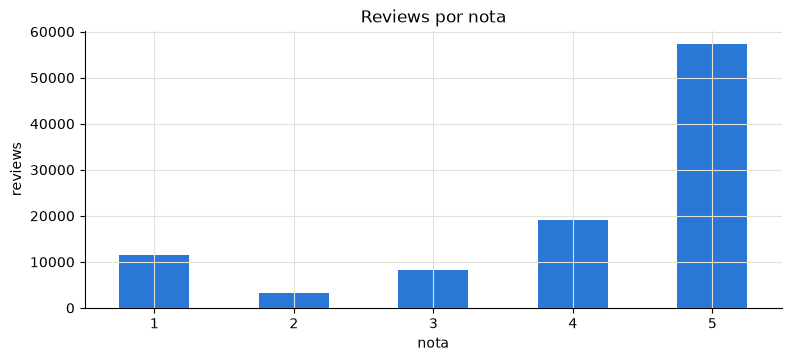

In [5]:
scores = q('SELECT review_score, COUNT(*) AS n FROM order_reviews GROUP BY 1 ORDER BY 1')
ax = scores.plot.bar(x='review_score', y='n', color=BLUE, legend=False, rot=0, width=0.5)
ax.set(title='Reviews por nota', xlabel='nota', ylabel='reviews');

## 5. Atraso em relação ao prazo prometido

A maior parte dos pedidos chega **antes** da data estimada (o Olist promete prazos folgados). A cauda à direita (atrasos) é pequena, mas é ali que a nota despenca.

count    96470.0
mean       -11.9
std         10.2
min       -147.0
25%        -17.0
50%        -12.0
75%         -7.0
max        188.0
Name: delay_days, dtype: float64

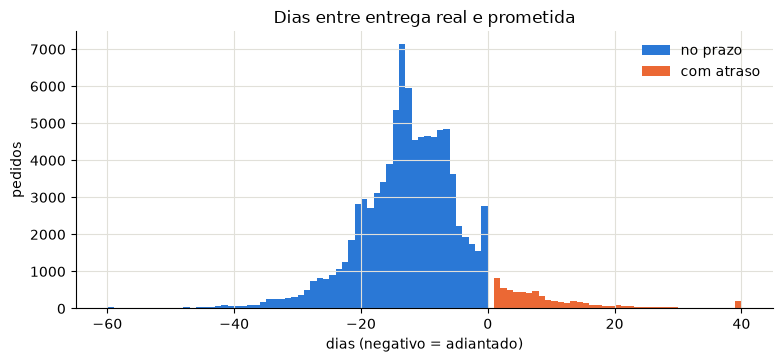

In [6]:
delay = q("""
    SELECT order_delivered_customer_date::date - order_estimated_delivery_date::date AS delay_days
    FROM orders
    WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
""")
clipped = delay.delay_days.clip(-60, 40)
fig, ax = plt.subplots()
ax.hist(clipped[clipped <= 0], bins=range(-60, 1), color=BLUE, label='no prazo')
ax.hist(clipped[clipped > 0], bins=range(1, 41), color=ORANGE, label='com atraso')
ax.set(title='Dias entre entrega real e prometida', xlabel='dias (negativo = adiantado)', ylabel='pedidos')
ax.legend(frameon=False)
delay.delay_days.describe().round(1)

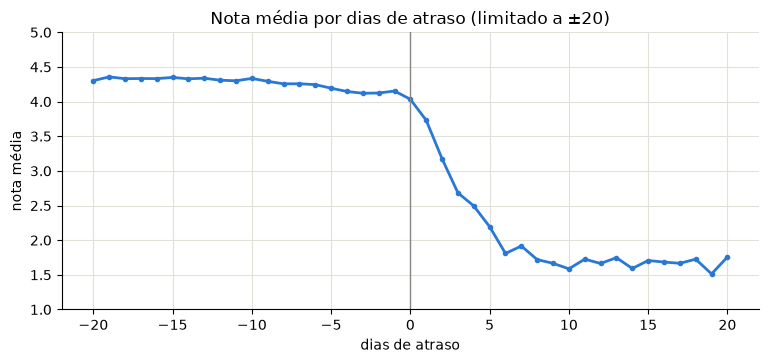

In [7]:
by_delay = q("""
    SELECT LEAST(GREATEST(o.order_delivered_customer_date::date - o.order_estimated_delivery_date::date, -20), 20) AS delay_days,
           AVG(r.review_score) AS avg_score, COUNT(*) AS n
    FROM orders o JOIN order_reviews r USING (order_id)
    WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
    GROUP BY 1 ORDER BY 1
""")
ax = by_delay.plot(x='delay_days', y='avg_score', color=BLUE, lw=2, legend=False, marker='o', ms=3)
ax.axvline(0, color='#898781', lw=1)
ax.set(title='Nota média por dias de atraso (limitado a ±20)', xlabel='dias de atraso', ylabel='nota média', ylim=(1, 5));

**Achado que guiou a pergunta 1:** enquanto o pedido chega no prazo, a nota varia pouco (de ~4,3 bem adiantado a ~4,0 no dia exato). A partir do 1º dia de atraso ela despenca: 3,7 no 1º dia, 2,7 no 3º e 2,2 no 5º. O que pesa é **cumprir a promessa**, mais do que a velocidade (hipótese confirmada entre estados na pergunta 5).

## 6. Recompra

`customer_id` é gerado por pedido. A identidade real do cliente é `customer_unique_id`.

In [8]:
freq = q("""
    SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS pedidos
    FROM orders o JOIN customers c USING (customer_id)
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
    GROUP BY 1
""")
freq.pedidos.clip(upper=4).value_counts(normalize=True).sort_index().rename('share').round(4)

pedidos
1    0.9696
2    0.0279
3    0.0020
4    0.0005
Name: share, dtype: float64

**~97% dos clientes compram uma única vez.** Isso inviabiliza quintis de frequência no RFM: em `src/rfm.py` a frequência vira uma regra explícita (comprou 2+ vezes ou não).

## 7. Qualidade dos dados

Resumo das checagens automatizadas em `src/quality.py` (também exibidas no site).

In [9]:
from src.quality import run_checks

pd.DataFrame(run_checks(engine))[['id', 'value', 'total', 'rate']]

  excluded_orders                    1,234 / 99,441
  orders_without_items                 775 / 99,441
  delivered_without_date                 8 / 96,478
  orders_multiple_reviews              547 / 98,673
  products_without_category            610 / 32,951
  categories_without_translation         2 / 73
  duplicate_reviews_removed              0 / 99,224


,id,value,total,rate
0,excluded_orders,1234,99441,0.0124
1,orders_without_items,775,99441,0.0078
2,delivered_without_date,8,96478,0.0001
3,orders_multiple_reviews,547,98673,0.0055
4,products_without_category,610,32951,0.0185
5,categories_without_translation,2,73,0.0274
6,duplicate_reviews_removed,0,99224,0.0000


## Próximos passos

As perguntas de negócio estão respondidas em `sql/analysis/` (uma query por pergunta), com estatística em `src/stats.py` e segmentação em `src/rfm.py`. Os resultados alimentam o site em `web/`.